             xGI    Points
xGI     1.000000  0.877374
Points  0.877374  1.000000


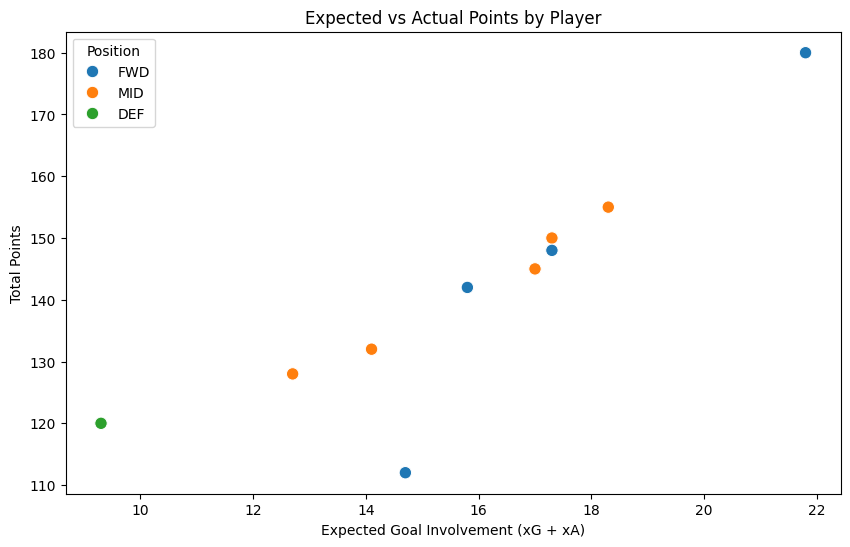

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("fpl_sample_data.csv")
data.head()

# Replace missing values and calculate efficiency metrics
data.fillna(0, inplace=True)
data["xGI"] = data["xG"] + data["xA"]  # expected goal involvement
data["Value_per_million"] = data["Points"] / data["Price"]

# Correlation between expected and actual performance
print(data[["xGI", "Points"]].corr())

# Identify undervalued players
undervalued = data.sort_values("Value_per_million", ascending=False).head(10)
undervalued[["Player", "Team", "xGI", "Points", "Value_per_million"]]

plt.figure(figsize=(10,6))
sns.scatterplot(data=data, x="xGI", y="Points", hue="Position", s=80)
plt.title("Expected vs Actual Points by Player")
plt.xlabel("Expected Goal Involvement (xG + xA)")
plt.ylabel("Total Points")
plt.show()